In [134]:
import numpy as np
import matplotlib.pyplot as plt

In [37]:
P = np.random.random((1000,3))

In [38]:
centroid = np.mean(P, axis=0)

In [39]:
nrm= P-centroid

In [40]:
print(nrm.shape)

(1000, 3)


In [41]:
Q = np.random.random((200,3))

In [42]:
diff = nrm[:,np.newaxis,:] - Q[np.newaxis,:,:]

In [43]:
print(diff.shape)

(1000, 200, 3)


In [44]:
D = np.linalg.norm(diff, axis=-1)

In [46]:
sq = (nrm**2).sum(-1)[:, None] + (Q**2).sum(-1)[None, :] - 2 * nrm @ Q.T
D2 = np.sqrt(np.maximum(sq, 0))   # clip tiny negatives from rounding
assert np.allclose(D, D2)

In [135]:
rng = np.random.default_rng(0)

In [136]:
N = rng.uniform(-np.pi,np.pi,size=(100000,2))

In [137]:
l1 = 0.30
l2 = 0.25
x = l1*np.cos(N[:,0]) + l2*np.cos(N[:,0]+N[:,1])
y = l1*np.sin(N[:,0]) + l2*np.sin(N[:,0]+N[:,1])
end_eff = np.array((x,y)).T

In [138]:
print(end_eff.shape)

(100000, 2)


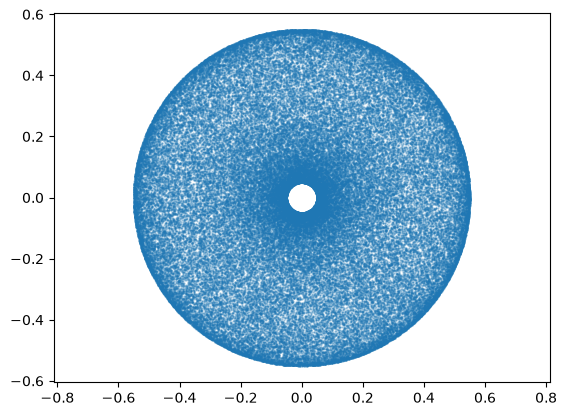

In [139]:
plt.scatter(x,y, s=0.5, alpha=0.3)
plt.axis("equal")
plt.show()

In [140]:
def fk(q, l1=0.30, l2=0.25):
    q1, q12 = q[:,0], q[:,0] + q[:,1]
    return np.stack([l1*np.cos(q1) + l2*np.cos(q12),
                     l1*np.sin(q1) + l2*np.sin(q12)], axis=-1)

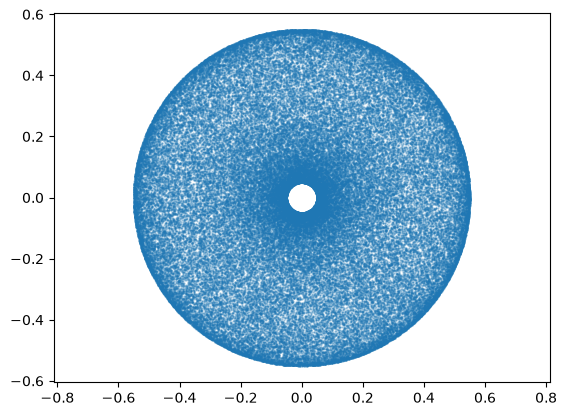

In [141]:
E = fk(N)
plt.scatter(E[:,0],E[:,1], s=0.5, alpha=0.3)
plt.axis("equal")
plt.show()

In [162]:
def fk_loop(q, l1=0.30, l2=0.25):
    q1, q12 = q[:,0], q[:,0] + q[:,1]
    result = np.empty_like(q)
    for i in range(q.shape[0]):
        result[i,0] = l1*np.cos(q1[i]) + l2*np.cos(q12[i])
        result[i,1] = l1*np.sin(q1[i]) + l2*np.sin(q12[i])
    return result

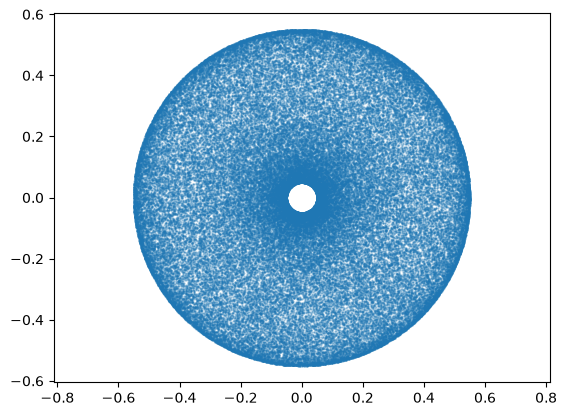

In [163]:
E_loop = fk_loop(N)
plt.scatter(E_loop[:,0],E_loop[:,1], s=0.5, alpha=0.3)
plt.axis("equal")
plt.show()

In [168]:
%timeit fk(N)
%timeit fk_loop(N)

5.79 ms ± 186 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
166 ms ± 5.79 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [ ]:
%timeit fk_loop(q)

In [193]:
def jacobian(q, l1=0.30, l2=0.25):
    q1, q12 = q[:,0], q[:,0] + q[:,1]
    return np.stack([np.stack([-l1*np.sin(q1) - l2*np.sin(q12),
                    -l1*np.sin(q1) - l2*np.sin(q12)], axis=-1), 
                    np.stack([-l2*np.sin(q12), l2*np.cos(q12)], axis=-1)], 
                    axis=-1)

In [194]:
j = jacobian(N)

In [195]:
print(j.shape)

(100000, 2, 2)


In [196]:
def central_diff(q, l1=0.30, l2=0.25, h =1e-6):
    q1ph, q12ph = q[:,0] + h, q[:,0] + q[:,1] + 2*h
    q1mh, q12mh = q[:,0] - h, q[:,0] + q[:,1] - 2*h
    Fph = np.stack([l1*np.cos(q1ph) + l2*np.cos(q12ph),
                     l1*np.sin(q1ph) + l2*np.sin(q12ph)], axis=-1)
    Fmh = np.stack([l1*np.cos(q1mh) + l2*np.cos(q12mh),
                     l1*np.sin(q1mh) + l2*np.sin(q12mh)], axis=-1)    
    return(Fph - Fmh)/(2*h)

In [197]:
j2 = central_diff(N)

In [198]:
print(j2.shape)

(100000, 2)


In [199]:
def jacobian_fd(f, q, h=1e-6):
    N, n = q.shape
    J = np.empty((N, 2, n))
    for j in range(n):              # loop over joints, not data points: fine
        e = np.zeros(n)
        e[j] = h                    # nudge joint j only
        J[:, :, j] = (f(q + e) - f(q - e)) / (2*h)
    return J

In [203]:
j3 = jacobian_fd(fk,N)


In [206]:
assert np.allclose(j @ np.array([1.0, 1.0]), central_diff(N))

AssertionError: 

In [207]:
assert np.allclose(j, j3)

AssertionError: 

In [208]:
print(j3.shape)

(100000, 2, 2)


In [209]:
print(j.shape)

(100000, 2, 2)
